(1461, 4) (48, 4)


<Axes: title={'center': 'Monthly sales'}, xlabel='date'>

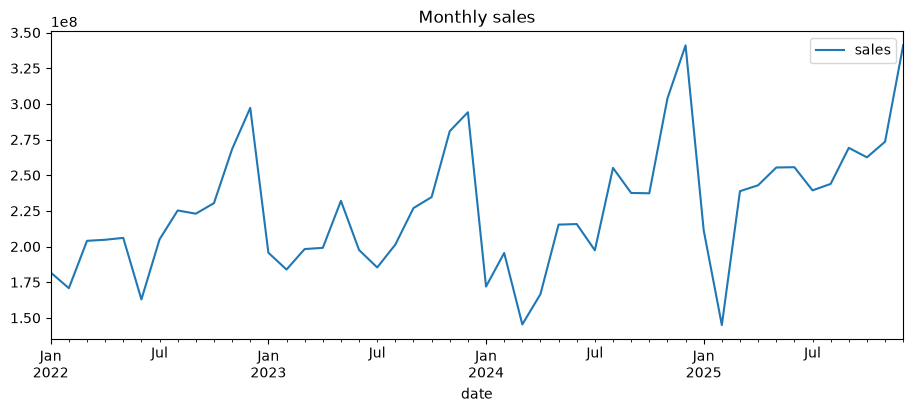

In [2]:
import pandas as pd, os

data = pd.read_parquet(r"D:\retailpulse\retailpulse_sales_clean.parquet",
                       columns=["date", "total_value", "quantity", "estimated_profit"])

# one row per day: total sales, units sold, profit
daily = data.groupby("date").agg(
    sales=("total_value", "sum"),
    units=("quantity", "sum"),
    profit=("estimated_profit", "sum"),
).reset_index()

# one row per month
monthly = daily.set_index("date").resample("MS").sum().reset_index()

os.makedirs(r"D:\retailpulse\app_data", exist_ok=True)       # small files for the web app
daily.to_csv(r"D:\retailpulse\app_data\daily_sales.csv", index=False)
monthly.to_csv(r"D:\retailpulse\app_data\monthly_sales.csv", index=False)

print(daily.shape, monthly.shape)
monthly.plot(x="date", y="sales", figsize=(11, 4), title="Monthly sales")

In [3]:
pip install statsmodels prophet

Note: you may need to restart the kernel to use updated packages.


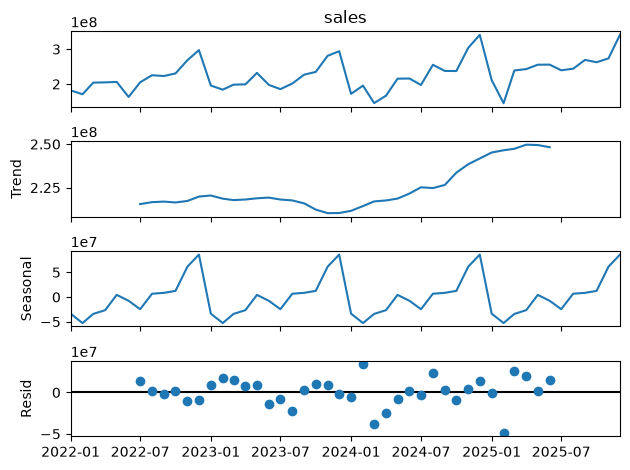

ADF p-value: 0.0041
Stationary (stable over time)? Yes


C:\Users\LAVANYA CHINNI\AppData\Local\Temp\ipykernel_14188\2538160867.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p = adfuller(series)[1]


In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt

series = monthly.set_index("date")["sales"]

result = seasonal_decompose(series, model="additive", period=12)   # 12 months = one cycle
result.plot()
plt.show()

p = adfuller(series)[1]
print("ADF p-value:", round(p, 4))
print("Stationary (stable over time)?", "Yes" if p < 0.05 else "No, it has a trend")

In [5]:
daily["weekday"] = daily["date"].dt.day_name()
print(daily.groupby("weekday")["sales"].mean().round(0).sort_values(ascending=False))

weekday
Wednesday    7463706.0
Thursday     7458860.0
Saturday     7451864.0
Tuesday      7444096.0
Friday       7439539.0
Monday       7431044.0
Sunday       7395609.0
Name: sales, dtype: float64


Importing plotly failed. Interactive plots will not work.
13:11:02 - cmdstanpy - INFO - Chain [1] start processing
13:11:03 - cmdstanpy - INFO - Chain [1] done processing


Prophet MAPE on the last 30 days: 7.66%


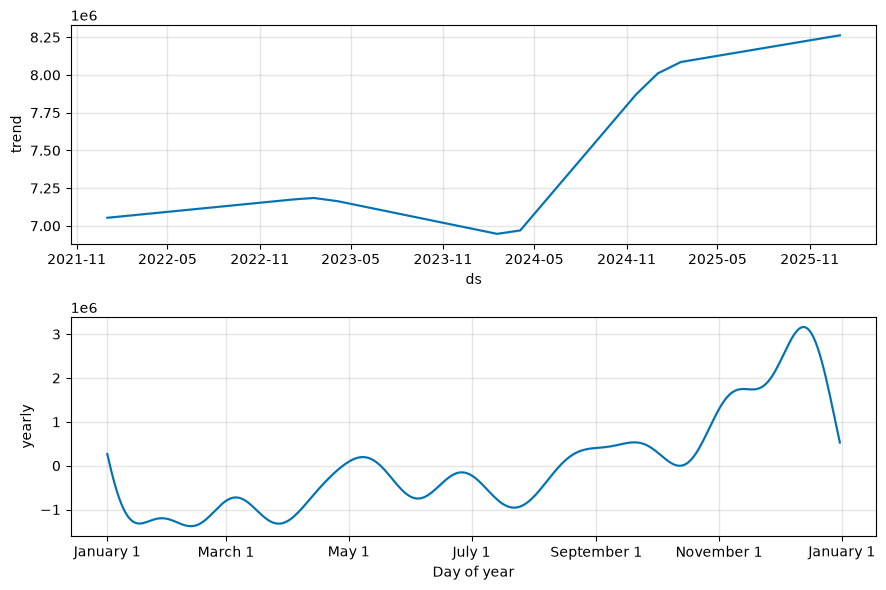

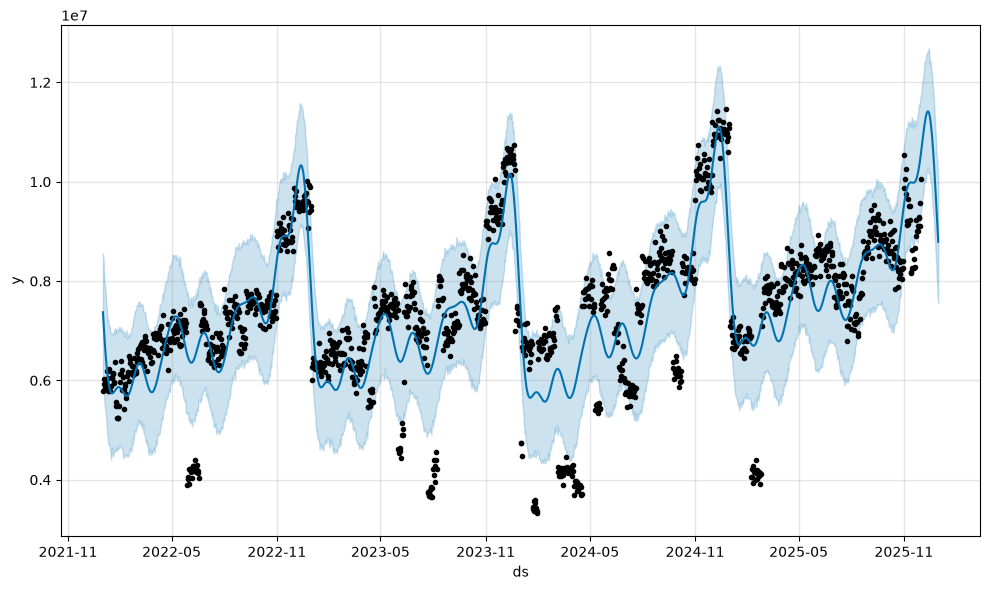

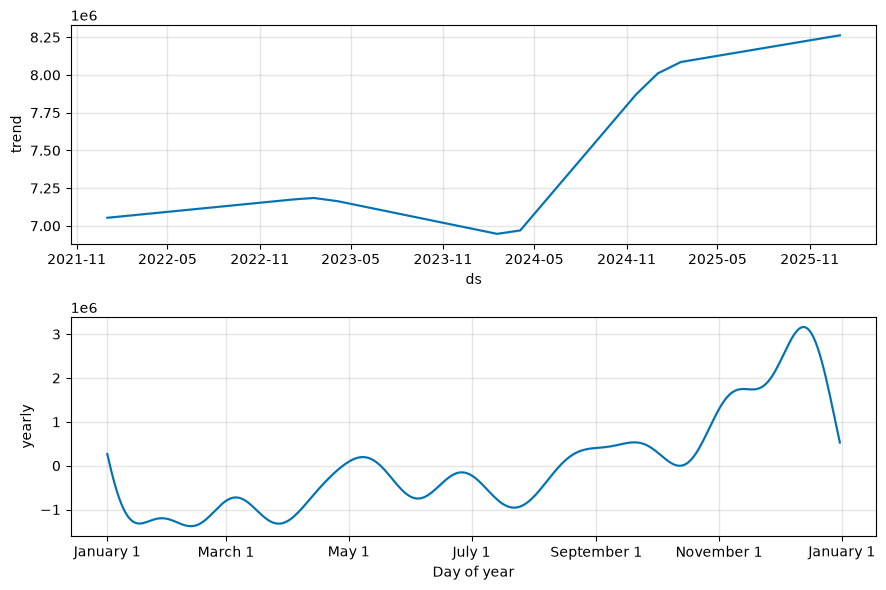

In [6]:
from prophet import Prophet
import numpy as np

# Prophet wants two columns named ds (date) and y (value)
df = daily[["date", "sales"]].rename(columns={"date": "ds", "sales": "y"})

train = df.iloc[:-30]    # everything except the last 30 days
test  = df.iloc[-30:]    # the last 30 days, which the model has never seen

model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
model.fit(train)

future   = model.make_future_dataframe(periods=30)
forecast = model.predict(future)

pred = forecast["yhat"].iloc[-30:].values
mape = np.mean(np.abs((test["y"].values - pred) / test["y"].values)) * 100
print(f"Prophet MAPE on the last 30 days: {mape:.2f}%")

model.plot(forecast)
model.plot_components(forecast)

unit_price: IQR outliers = 534,485 | Z-score outliers = 223,513
quantity: IQR outliers = 0 | Z-score outliers = 0
total_value: IQR outliers = 941,551 | Z-score outliers = 226,054


unit_price        Axes(0.125,0.11;0.352273x0.77)
total_value    Axes(0.547727,0.11;0.352273x0.77)
dtype: object

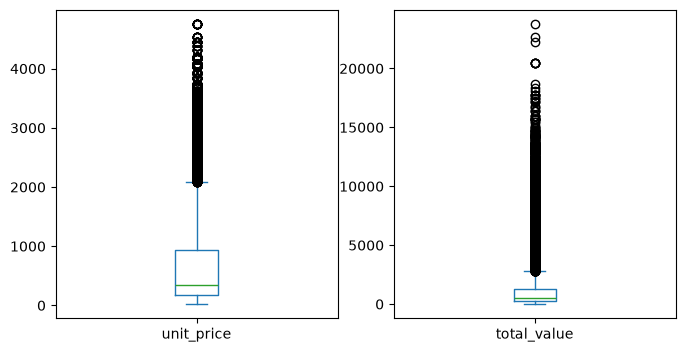

In [7]:
sales = pd.read_parquet(r"D:\retailpulse\retailpulse_sales_clean.parquet",
                        columns=["unit_price", "quantity", "total_value"])

for col in ["unit_price", "quantity", "total_value"]:
    s = sales[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_out = ((s < low) | (s > high)).sum()
    z_out = (((s - s.mean()) / s.std()).abs() > 3).sum()
    print(f"{col}: IQR outliers = {iqr_out:,} | Z-score outliers = {z_out:,}")

sales.sample(100_000, random_state=1)[["unit_price", "total_value"]].plot(kind="box", subplots=True, figsize=(8, 4))

In [8]:
# 1) the test: actual vs predicted for the last 30 days (for the report chart)
test_out = test.copy()
test_out["predicted"] = pred
test_out.to_csv(r"D:\retailpulse\app_data\prophet_test.csv", index=False)

# 2) retrain on ALL data and predict the next 30 days (Jan 2026) for the app
final_model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
final_model.fit(df)
next30 = final_model.predict(final_model.make_future_dataframe(periods=30))
next30[["ds", "yhat", "yhat_lower", "yhat_upper"]].to_csv(r"D:\retailpulse\app_data\prophet_forecast.csv", index=False)

print(next30[["ds", "yhat"]].tail(5))

13:11:07 - cmdstanpy - INFO - Chain [1] start processing
13:11:07 - cmdstanpy - INFO - Chain [1] done processing


             ds          yhat
1486 2026-01-26  7.091861e+06
1487 2026-01-27  7.106115e+06
1488 2026-01-28  7.117283e+06
1489 2026-01-29  7.124891e+06
1490 2026-01-30  7.128667e+06


In [9]:
daily["typical"] = daily["sales"].rolling(31, center=True, min_periods=10).median()
daily["ratio"] = daily["sales"] / daily["typical"]
low_days = daily[daily["ratio"] < 0.75]

print(len(low_days), "unusually low days")
print(low_days["date"].dt.to_period("M").value_counts().sort_index())

32 unusually low days
date
2023-06    10
2024-01    12
2024-05    10
Freq: M, Name: count, dtype: int64


In [10]:
for cut in [0.75, 0.85]:
    d = daily[daily["ratio"] < cut]
    print(f"ratio < {cut}: {len(d)} days")
    print(d.groupby(d["date"].dt.to_period("M"))["date"].agg(["count", "min", "max"]))
    print()

ratio < 0.75: 32 days
         count        min        max
date                                
2023-06     10 2023-06-01 2023-06-10
2024-01     12 2024-01-01 2024-01-30
2024-05     10 2024-05-10 2024-05-19

ratio < 0.85: 46 days
         count        min        max
date                                
2023-04      8 2023-04-11 2023-04-18
2023-06     11 2023-06-01 2023-06-11
2023-07      5 2023-07-23 2023-07-31
2024-01     12 2024-01-01 2024-01-30
2024-05     10 2024-05-10 2024-05-19



In [11]:
cols = ["date", "store_id", "channel", "category", "total_value"]
s = pd.read_parquet(r"D:\retailpulse\retailpulse_sales_clean.parquet", columns=cols)
low_dates = daily.loc[daily["ratio"] < 0.75, "date"]
s["low_day"] = s["date"].isin(low_dates)

spd = s.groupby("date")["store_id"].nunique()
print("Stores selling per day -> low days:", round(spd[spd.index.isin(low_dates)].mean(), 1),
      "| normal days:", round(spd[~spd.index.isin(low_dates)].mean(), 1))

for col in ["channel", "category"]:
    share = s.groupby(["low_day", col], observed=True)["total_value"].sum().unstack(0)
    share = (share / share.sum()).round(3)
    share.columns = ["normal", "low"]
    print(share, "\n")

Stores selling per day -> low days: 30.0 | normal days: 30.0
            normal    low
channel                  
In-Store     0.553  0.551
Mobile App   0.150  0.151
Online       0.297  0.298 

                           normal    low
category                                
Apparel & Footwear          0.176  0.183
Beverages                   0.017  0.017
Dairy & Bakery              0.032  0.032
Electronics & Accessories   0.214  0.208
Frozen Foods                0.075  0.073
Grocery                     0.032  0.031
Health & Wellness           0.082  0.080
Home & Kitchen              0.145  0.154
Home Care                   0.039  0.038
Personal Care               0.148  0.146
Snacks & Confectionery      0.012  0.012
Stationery & Office         0.028  0.028 



In [12]:
pip install torch --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.


In [13]:
import torch
print(torch.__version__)

2.14.1+cpu


In [14]:
import numpy as np, torch, torch.nn as nn
from sklearn.preprocessing import MinMaxScaler

LOOK, HORIZON = 60, 30                       # look at 60 days, predict 30 days

sales = daily["sales"].values.reshape(-1, 1)
doy = daily["date"].dt.dayofyear.values       # day of year, 1 to 366
cal = np.c_[np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25)]

split = len(daily) - HORIZON                  # last 30 days are the test, same as Prophet
scaler = MinMaxScaler().fit(sales[:split])    # scale using training days only
s = scaler.transform(sales)
feat = np.c_[s, cal]                          # 3 inputs per day

X, y = [], []
for i in range(LOOK, split - HORIZON + 1):    # every 60-day window with 30 known days after it
    X.append(feat[i-LOOK:i])
    y.append(s[i:i+HORIZON, 0])
X = torch.tensor(np.array(X), dtype=torch.float32)
y = torch.tensor(np.array(y), dtype=torch.float32)
print(X.shape, y.shape)

torch.Size([1342, 60, 3]) torch.Size([1342, 30])


In [15]:
class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=3, hidden_size=64, batch_first=True)
        self.out = nn.Linear(64, HORIZON)
    def forward(self, x):
        o, _ = self.lstm(x)
        return self.out(o[:, -1, :])          # use the last step to predict all 30 days

torch.manual_seed(42)
model = LSTMModel()
opt = torch.optim.Adam(model.parameters(), lr=0.005)
loss_fn = nn.MSELoss()

for epoch in range(150):
    opt.zero_grad()
    loss = loss_fn(model(X), y)
    loss.backward()
    opt.step()
    if epoch % 30 == 0:
        print("epoch", epoch, "loss", round(loss.item(), 5))

epoch 0 loss 0.29962
epoch 30 loss 0.02764
epoch 60 loss 0.02184
epoch 90 loss 0.01809
epoch 120 loss 0.01799


Prophet MAPE:  7.66%
LSTM MAPE:     10.62%
Ensemble MAPE: 7.73%


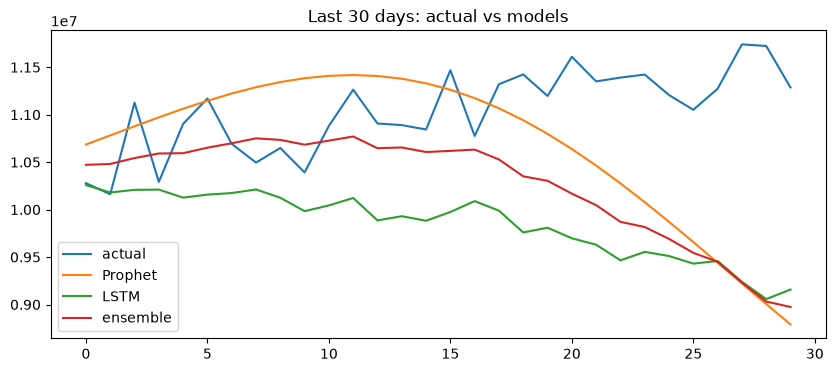

In [16]:
model.eval()
with torch.no_grad():
    last = torch.tensor(feat[split-LOOK:split][None], dtype=torch.float32)
    lstm_pred = scaler.inverse_transform(model(last).numpy().reshape(-1, 1)).ravel()

actual = daily["sales"].values[split:]
def mape(a, p): return np.mean(np.abs((a - p) / a)) * 100

print(f"Prophet MAPE:  {mape(actual, pred):.2f}%")
print(f"LSTM MAPE:     {mape(actual, lstm_pred):.2f}%")
print(f"Ensemble MAPE: {mape(actual, (pred + lstm_pred) / 2):.2f}%")

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
plt.plot(actual, label="actual"); plt.plot(pred, label="Prophet")
plt.plot(lstm_pred, label="LSTM"); plt.plot((pred + lstm_pred) / 2, label="ensemble")
plt.legend(); plt.title("Last 30 days: actual vs models"); plt.show()

In [17]:
results = pd.DataFrame({
    "date": daily["date"].values[split:],
    "actual": actual,
    "prophet": pred,
    "lstm": lstm_pred,
    "ensemble": (pred + lstm_pred) / 2,
})
results.to_csv(r"D:\retailpulse\app_data\forecast_test_results.csv", index=False)

comparison = pd.DataFrame({
    "model": ["Prophet", "LSTM", "Ensemble"],
    "MAPE_percent": [mape(actual, pred), mape(actual, lstm_pred), mape(actual, (pred + lstm_pred) / 2)],
}).round(2)
comparison.to_csv(r"D:\retailpulse\app_data\model_comparison.csv", index=False)
comparison

,model,MAPE_percent
0,Prophet,7.66
1,LSTM,10.62
2,Ensemble,7.73


In [18]:
cut = pd.Timestamp("2025-09-01")
tr = df[df["ds"] < cut]
te = df[(df["ds"] >= cut) & (df["ds"] < cut + pd.Timedelta(days=30))]

m2 = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False).fit(tr)
p2 = m2.predict(te[["ds"]])["yhat"].values
print(f"Prophet MAPE, Sep 2025 window: {np.mean(np.abs((te['y'].values - p2) / te['y'].values)) * 100:.2f}%")

13:18:20 - cmdstanpy - INFO - Chain [1] start processing
13:18:20 - cmdstanpy - INFO - Chain [1] done processing


Prophet MAPE, Sep 2025 window: 3.04%
